# 07 · 가상 스크리닝과 분자 도킹
### 실습으로 배우는 신약개발 AI — 강의 목차 ⑨ 가상 스크리닝과 분자 도킹

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/DrugAI/blob/main/07_Virtual_Screening_Docking.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | ① 가상 스크리닝 깔때기(유사도 → 약물다움·PAINS 필터 → QSAR → 도킹) ② **농축도(Enrichment)** 로 스크리닝 성능 평가 ③ **AutoDock Vina 실제 도킹** — 재도킹(redocking)으로 프로토콜 검증 ④ 결합 자세 3D 시각화와 상호작용 해석 |
| **표적 / 데이터** | 알츠하이머 표적 **BACE-1** (PDB **4B05**, 임상후보 AZD3839 결합 구조) · BACE 저해제 1,513개 |
| **실행 환경** | CPU · 약 15분 (도킹 1개당 약 15~40초) |

```
라이브러리(수백만) → ① 리간드 기반 유사도 → ② 약물다움·PAINS 필터 → ③ QSAR 활성 예측 → ④ 구조 기반 도킹 → 실험 검증(수십 개)
```

In [1]:
# 도킹 도구 설치: AutoDock Vina(도킹 엔진), Meeko(리간드 준비), OpenBabel(수용체 준비), py3Dmol(3D 시각화)
%pip install -q rdkit koreanize-matplotlib vina meeko gemmi openbabel-wheel py3Dmol
import koreanize_matplotlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests, time
import warnings; warnings.filterwarnings("ignore")
from rdkit import Chem, DataStructs, RDLogger; RDLogger.DisableLog("rdApp.*")
from rdkit.Chem import AllChem, Draw, Descriptors, Crippen, rdFingerprintGenerator, rdMolAlign
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams
print("✅ 준비 완료")

Note: you may need to restart the kernel to use updated packages.


✅ 준비 완료


## 가상 스크리닝(VS)의 두 갈래
| | 리간드 기반 (LBVS) | 구조 기반 (SBVS) |
|---|---|---|
| 필요한 정보 | 알려진 활성 물질 | 표적 단백질 3D 구조 |
| 방법 | 유사도 검색, 약효단(pharmacophore), QSAR | **분자 도킹**, 딥러닝 도킹(DiffDock 등) |
| 속도 | 매우 빠름 (수억 개 가능) | 느림 (분자당 수 초~분) |
| 장점 | 구조 없이 가능 | 새로운 골격(scaffold hopping) 발견 가능 |

## 0. 스크리닝 시뮬레이션 설계
실제 상황을 흉내 내기 위해 BACE 데이터를 반으로 나눕니다.
- **알려진 데이터(50%)**: 활성을 이미 아는 화합물 → 유사도 질의, QSAR 학습에 사용
- **스크리닝 라이브러리(50%)**: 활성을 모른다고 가정 → 스크리닝 대상 (정답은 성능 평가에만 사용)

In [2]:
bace = pd.read_csv("https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/bace.csv")[["mol", "pIC50", "Class"]]
bace["m"] = bace["mol"].apply(Chem.MolFromSmiles)
bace = bace[bace["m"].notna()].reset_index(drop=True)
morgan = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
bace["fp"] = bace["m"].apply(morgan.GetFingerprint)

rng = np.random.RandomState(7)
is_lib = rng.rand(len(bace)) < 0.5
known, lib = bace[~is_lib].reset_index(drop=True), bace[is_lib].reset_index(drop=True)
print(f"알려진 화합물 {len(known)}개 (활성 {known.Class.sum()}) / 스크리닝 라이브러리 {len(lib)}개 (숨겨진 활성 {lib.Class.sum()})")

알려진 화합물 745개 (활성 338) / 스크리닝 라이브러리 768개 (숨겨진 활성 353)


## ① 리간드 기반 유사도 검색
질의(query) = 알려진 데이터 중 **가장 강력한 저해제 5개**. 라이브러리 각 분자의 점수 = 5개 질의와의 **최대 Tanimoto 유사도**.

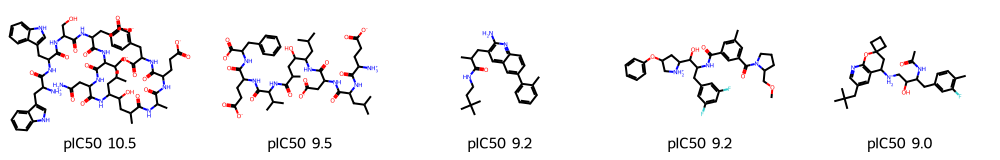

In [3]:
queries = known.sort_values("pIC50", ascending=False).head(5)
lib["sim"] = [max(DataStructs.BulkTanimotoSimilarity(f, list(queries["fp"]))) for f in lib["fp"]]
Draw.MolsToGridImage(list(queries["m"]), molsPerRow=5, subImgSize=(200, 160), legends=[f"pIC50 {p:.1f}" for p in queries["pIC50"]])

### 스크리닝 성능 평가 — 농축도(Enrichment Factor)
**EF(x%)** = (상위 x% 안의 활성 비율) / (전체 라이브러리의 활성 비율). EF=1 이면 무작위 선택과 같음.

In [4]:
from sklearn.metrics import roc_auc_score
def enrichment(score, active, frac):
    n = max(1, int(len(score) * frac))
    top = np.argsort(-np.asarray(score))[:n]
    return active[top].mean() / active.mean()

act = lib["Class"].values
print(f"유사도 검색  ROC-AUC = {roc_auc_score(act, lib['sim']):.3f}")
for f in [0.01, 0.05, 0.10]:
    print(f"  EF {int(f*100):2d}% = {enrichment(lib['sim'], act, f):.2f}  (상위 {int(len(lib)*f)}개 중 활성 비율 {act[np.argsort(-lib['sim'].values)[:int(len(lib)*f)]].mean():.0%})")

유사도 검색  ROC-AUC = 0.593
  EF  1% = 2.18  (상위 7개 중 활성 비율 100%)
  EF  5% = 2.12  (상위 38개 중 활성 비율 97%)
  EF 10% = 1.75  (상위 76개 중 활성 비율 80%)


## ② 약물다움 + PAINS 필터
- **Lipinski**(분자량·LogP·HBD·HBA) + **Veber**(회전결합 ≤ 10, TPSA ≤ 140): 경구 흡수 가능성
- **PAINS**(Pan-Assay INterference compoundS): 여러 분석에서 **가짜 양성**을 내는 반응성/간섭 구조 → 제거

In [5]:
params = FilterCatalogParams(); params.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
pains = FilterCatalog(params)
def drug_filter(m):
    mw, logp = Descriptors.MolWt(m), Crippen.MolLogP(m)
    lip = sum([mw > 500, logp > 5, Descriptors.NumHDonors(m) > 5, Descriptors.NumHAcceptors(m) > 10]) <= 1
    veber = Descriptors.NumRotatableBonds(m) <= 10 and Descriptors.TPSA(m) <= 140
    return lip, veber, pains.HasMatch(m)
f = lib["m"].apply(drug_filter)
lib["Lipinski"], lib["Veber"], lib["PAINS"] = zip(*f)
lib["pass_filter"] = lib["Lipinski"] & lib["Veber"] & ~lib["PAINS"]
print("Lipinski 통과:", lib.Lipinski.sum(), "/ Veber 통과:", lib.Veber.sum(), "/ PAINS 경고:", lib.PAINS.sum(),
      "→ 최종 통과:", lib.pass_filter.sum(), "/", len(lib))

Lipinski 통과: 740 / Veber 통과: 566 / PAINS 경고: 0 → 최종 통과: 563 / 768


## ③ QSAR 활성 예측 (리간드 기반 머신러닝)
알려진 데이터로 **활성(Class) 분류 모델**을 학습해 라이브러리 분자의 활성 확률을 예측합니다 (예제 04·06 의 기법).

In [6]:
from sklearn.ensemble import RandomForestClassifier
Xk = np.array([morgan.GetCountFingerprintAsNumPy(m) for m in known["m"]])
Xl = np.array([morgan.GetCountFingerprintAsNumPy(m) for m in lib["m"]])
qsar = RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=0).fit(Xk, known["Class"])
lib["p_active"] = qsar.predict_proba(Xl)[:, 1]
lib["combo"] = 0.5 * lib["p_active"] + 0.5 * lib["sim"]            # 두 점수의 단순 평균(데이터 융합)

rows = []
for name, s in [("유사도", lib["sim"]), ("QSAR 확률", lib["p_active"]), ("유사도+QSAR", lib["combo"])]:
    rows.append({"방법": name, "ROC-AUC": roc_auc_score(act, s), "EF 1%": enrichment(s, act, .01),
                 "EF 5%": enrichment(s, act, .05), "EF 10%": enrichment(s, act, .10)})
pd.DataFrame(rows).round(2)

,방법,ROC-AUC,EF 1%,EF 5%,EF 10%
0,유사도,0.59,2.18,2.12,1.75
1,QSAR 확률,0.89,2.18,2.12,2.00
2,유사도+QSAR,0.89,2.18,2.12,1.98


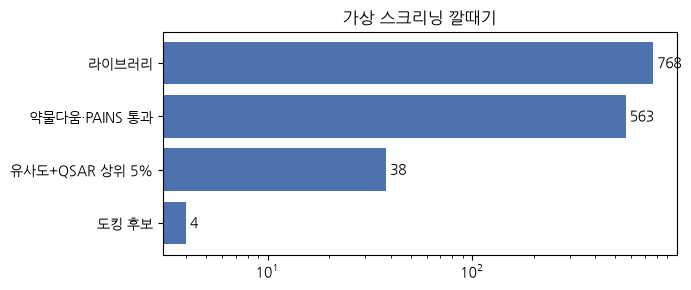

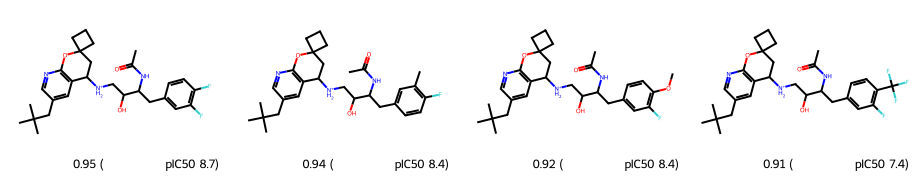

In [7]:
# 스크리닝 깔때기 → 도킹할 상위 후보 선정
funnel = lib[lib["pass_filter"]].sort_values("combo", ascending=False)
top = funnel.head(4).copy()
counts = {"라이브러리": len(lib), "약물다움·PAINS 통과": int(lib.pass_filter.sum()),
          "유사도+QSAR 상위 5%": int(len(lib) * 0.05), "도킹 후보": len(top)}
plt.figure(figsize=(7, 3)); plt.barh(list(counts)[::-1], list(counts.values())[::-1], color="#4C72B0")
for i, v in enumerate(list(counts.values())[::-1]): plt.text(v, i, f" {v}", va="center")
plt.xscale("log"); plt.title("가상 스크리닝 깔때기"); plt.tight_layout(); plt.show()
Draw.MolsToGridImage(list(top["m"]), molsPerRow=4, subImgSize=(230, 180),
                     legends=[f"점수 {c:.2f} (실제 pIC50 {p:.1f})" for c, p in zip(top["combo"], top["pIC50"])])

## ④ 분자 도킹 (AutoDock Vina) — 구조 기반 가상 스크리닝
**도킹 = ① 결합 자세 탐색(search) + ② 점수 계산(scoring)**
- Vina 점수(kcal/mol): 입체 맞물림 + 소수성 + 수소결합 − 회전 자유도 손실. **더 음수일수록 강한 결합**
- 절차: 수용체·리간드를 **PDBQT**(전하 Q, 원자형 T 포함) 형식으로 준비 → 결합부위에 **탐색 상자** 지정 → 도킹

### 4-1. 수용체 준비 (PDB 4B05: BACE-1 + AZD3839)

In [8]:
pdb_txt = requests.get("https://files.rcsb.org/download/4B05.pdb", timeout=60).text
protein = [l for l in pdb_txt.splitlines() if l.startswith("ATOM")]                       # 단백질 원자만
xtal_lines = [l for l in pdb_txt.splitlines() if l.startswith("HETATM") and l[17:20] == "32D"]   # 결합 리간드
open("receptor.pdb", "w").write("\n".join(protein) + "\nEND\n")
open("xtal_ligand.pdb", "w").write("\n".join(xtal_lines) + "\nEND\n")
print("단백질 원자:", len(protein), " / 결합 리간드(AZD3839, 코드 32D) 원자:", len(xtal_lines))

from openbabel import pybel
rec = next(pybel.readfile("pdb", "receptor.pdb"))
rec.OBMol.AddPolarHydrogens()                                    # 극성 수소 추가 (수소결합 계산용)
rec.write("pdbqt", "receptor.pdbqt", overwrite=True, opt={"r": None})   # r = 고정(rigid) 수용체
print("receptor.pdbqt 생성 완료")

AZD3839 = "NC1=N[C@@](c2cccc(c2)c3cncnc3)(c4ccnc(c4)C(F)F)c5cccc(F)c15"
xtal = AllChem.AssignBondOrdersFromTemplate(Chem.MolFromSmiles(AZD3839), Chem.MolFromPDBFile("xtal_ligand.pdb"))
center = xtal.GetConformer().GetPositions().mean(axis=0)
print("탐색 상자 중심(결합 리간드 중심):", center.round(2))

단백질 원자: 2921  / 결합 리간드(AZD3839, 코드 32D) 원자: 32


receptor.pdbqt 생성 완료
탐색 상자 중심(결합 리간드 중심): [  5.37   1.93 -20.89]


*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is receptor.pdb)



### 4-2. 리간드 준비와 도킹 함수

In [9]:
from meeko import MoleculePreparation, PDBQTWriterLegacy, PDBQTMolecule, RDKitMolCreate
from vina import Vina

def ligand_pdbqt(smiles, seed=42):
    m = Chem.AddHs(Chem.MolFromSmiles(smiles))
    AllChem.EmbedMolecule(m, randomSeed=seed); AllChem.MMFFOptimizeMolecule(m)    # 3D 좌표 + 에너지 최소화
    setup = MoleculePreparation().prepare(m)[0]
    return PDBQTWriterLegacy.write_string(setup)[0]

v = Vina(sf_name="vina", verbosity=0, seed=1)
v.set_receptor("receptor.pdbqt")
v.compute_vina_maps(center=center.tolist(), box_size=[22, 22, 22])      # 결합부위 주변 22Å 상자

def dock(smiles, n_poses=5, exhaustiveness=8):
    v.set_ligand_from_string(ligand_pdbqt(smiles))
    v.dock(exhaustiveness=exhaustiveness, n_poses=n_poses)
    pose = RDKitMolCreate.from_pdbqt_mol(PDBQTMolecule(v.poses(n_poses=n_poses), is_dlg=False, skip_typing=True))[0]
    return v.energies(n_poses=n_poses)[:, 0], pose

### 4-3. ⭐ 재도킹(Redocking)으로 도킹 프로토콜 검증
결정 구조의 리간드를 다시 도킹해 **실험 자세를 재현하는지(RMSD < 2 Å)** 확인합니다. 재현하지 못하면 그 설정으로 스크리닝하면 안 됩니다.

In [10]:
t = time.time()
e_ref, pose_ref = dock(AZD3839)
rms = [rdMolAlign.CalcRMS(Chem.RemoveHs(Chem.Mol(pose_ref, confId=i)), Chem.RemoveHs(xtal)) for i in range(pose_ref.GetNumConformers())]
print(f"도킹 시간 {time.time()-t:.0f}초")
print(pd.DataFrame({"자세": range(1, len(e_ref) + 1), "Vina 점수(kcal/mol)": e_ref.round(2), "결정구조 대비 RMSD(Å)": np.round(rms, 2)}).to_string(index=False))
print("\n→ 1순위 자세 RMSD", round(rms[0], 2), "Å :", "✅ 프로토콜 검증 통과 (< 2 Å)" if rms[0] < 2 else "⚠️ 재현 실패 — 설정 재검토")

도킹 시간 7초
 자세  Vina 점수(kcal/mol)  결정구조 대비 RMSD(Å)
  1             -10.76             0.64
  2             -10.09             3.01
  3             -10.04             4.36
  4              -9.87             6.42
  5              -9.79             7.89

→ 1순위 자세 RMSD 0.64 Å : ✅ 프로토콜 검증 통과 (< 2 Å)


### 4-4. 스크리닝 후보 도킹
선정된 후보 4개와, 비교를 위한 **약한 저해제(음성 대조군)** 1개를 도킹합니다.

In [11]:
neg = lib[lib["pass_filter"]].sort_values("pIC50").iloc[0]          # 활성이 가장 낮은 분자 (음성 대조)
to_dock = [("AZD3839 (기준)", AZD3839, np.nan)] + \
          [(f"후보{i+1}", Chem.MolToSmiles(r.m), r.pIC50) for i, r in enumerate(top.itertuples())] + \
          [("음성대조", Chem.MolToSmiles(neg.m), neg.pIC50)]
dock_rows, poses = [], {}
for name, smi, p in to_dock:
    t = time.time()
    e, pose = (e_ref, pose_ref) if name.startswith("AZD") else dock(smi)
    poses[name] = pose
    ha = Chem.MolFromSmiles(smi).GetNumHeavyAtoms()
    dock_rows.append({"화합물": name, "Vina 점수": round(e[0], 2), "리간드 효율(LE)": round(-e[0] / ha * 1.0, 3),
                      "무거운 원자 수": ha, "실제 pIC50(숨김 정보)": p})
    print(f"{name:12s} {e[0]:6.2f} kcal/mol  ({time.time()-t:.0f}s)")
dock_df = pd.DataFrame(dock_rows)
dock_df

AZD3839 (기준) -10.76 kcal/mol  (0s)


후보1           -9.72 kcal/mol  (17s)


후보2           -8.83 kcal/mol  (19s)


후보3           -8.61 kcal/mol  (24s)


후보4           -9.65 kcal/mol  (22s)


음성대조          -8.86 kcal/mol  (2s)


,화합물,Vina 점수,리간드 효율(LE),무거운 원자 수,실제 pIC50(숨김 정보)
0,AZD3839 (기준),-10.76,0.336,32,NaN
1,후보1,-9.72,0.270,36,8.698970
2,후보2,-8.83,0.245,36,8.397940
3,후보3,-8.61,0.233,37,8.443698
4,후보4,-9.65,0.248,39,7.356547
5,음성대조,-8.86,0.467,19,2.953115


> **해석 주의**
> - 도킹 점수는 **결합 자세 예측**에는 강하지만, **활성의 정확한 순위**와는 상관이 약한 경우가 많습니다 (용매화·유연성·엔트로피 단순화).
> - **리간드 효율(LE = −점수/무거운 원자 수)**: 큰 분자가 점수만 좋아 보이는 효과를 보정
> - 실무: 도킹은 **가상 스크리닝 후반부 필터 + 결합 가설 수립** 용도, 최종 판단은 실험(IC50)으로

## 5. 3D 시각화 — 결합 자세 비교
- 회색 리본: BACE-1 단백질 · 하늘색 막대: 결합부위 잔기
- **초록**: 결정 구조의 AZD3839 (실험) · **자홍**: 재도킹 자세 · **주황**: 후보1 도킹 자세

In [ ]:
import py3Dmol, base64, sys
from IPython.display import HTML, display
IN_COLAB = "google.colab" in sys.modules
JS_URL = "https://3dmol.org/build/3Dmol.js"          # CDN 주소를 명시해 로딩 실패를 방지

def viewer(width=740, height=500):
    return py3Dmol.view(width=width, height=height, js=JS_URL)

def show3d(view, width=760, height=520):
    # Colab 에서는 기본 렌더링이 가장 안정적, 로컬 Jupyter 는 iframe 으로 격리
    if IN_COLAB:
        view.show()
    else:
        b64 = base64.b64encode(view._make_html().encode()).decode()
        display(HTML(f'<iframe src="data:text/html;base64,{b64}" width="{width}" height="{height}" style="border:1px solid #ddd"></iframe>'))

view = viewer(740, 500)
view.addModel(open("receptor.pdb").read(), "pdb")
view.setStyle({"cartoon": {"color": "lightgray"}})
view.addModel(Chem.MolToMolBlock(xtal), "mol");                                  view.setStyle({"model": 1}, {"stick": {"colorscheme": "greenCarbon", "radius": 0.25}})
view.addModel(Chem.MolToMolBlock(Chem.Mol(pose_ref, confId=0)), "mol");          view.setStyle({"model": 2}, {"stick": {"colorscheme": "magentaCarbon", "radius": 0.15}})
view.addModel(Chem.MolToMolBlock(Chem.Mol(poses["후보1"], confId=0)), "mol");    view.setStyle({"model": 3}, {"stick": {"colorscheme": "orangeCarbon", "radius": 0.15}})
view.addStyle({"model": 0, "within": {"distance": 4.5, "sel": {"model": 1}}}, {"stick": {"colorscheme": "cyanCarbon", "radius": 0.12}})
view.zoomTo({"model": 1})
show3d(view)

## 6. 결합 상호작용 해석 — 촉매 아스파르트산(Asp32·Asp228)
BACE-1 은 **아스파르트산 프로테아제**입니다. 강력한 저해제의 **아미딘(–C(=N)–NH₂)** 기는 두 촉매 잔기 **Asp32, Asp228** 과 수소결합/염다리를 형성합니다.
도킹 자세의 질소 원자와 두 아스파르트산 산소 사이 거리를 계산해 봅니다 (≤ 3.5 Å 이면 수소결합 가능).

In [13]:
asp_O = {}
for l in protein:
    resn, resi, atom = l[17:20], int(l[22:26]), l[12:16].strip()
    if resn == "ASP" and resi in (32, 228) and atom in ("OD1", "OD2"):
        asp_O[f"Asp{resi}-{atom}"] = np.array([float(l[30:38]), float(l[38:46]), float(l[46:54])])

def min_N_dist(mol):
    m = Chem.Mol(mol, confId=0) if mol.GetNumConformers() > 0 else mol
    pos = m.GetConformer(0).GetPositions()
    Ns = [i for i, a in enumerate(m.GetAtoms()) if a.GetSymbol() == "N"]
    return {k: round(min(np.linalg.norm(pos[i] - o) for i in Ns), 2) for k, o in asp_O.items()}

rows = [{"구조": "결정구조 AZD3839", **min_N_dist(xtal)}] + [{"구조": f"도킹 {k}", **min_N_dist(p)} for k, p in poses.items()]
pd.DataFrame(rows)

,구조,Asp32-OD1,Asp32-OD2,Asp228-OD1,Asp228-OD2
0,결정구조 AZD3839,2.84,2.58,2.82,2.90
1,도킹 AZD3839 (기준),3.10,2.94,2.99,2.90
2,도킹 후보1,5.90,5.52,5.18,3.98
3,도킹 후보2,6.90,5.20,6.20,4.72
4,도킹 후보3,5.62,4.60,6.40,5.46
5,도킹 후보4,4.68,4.17,5.07,4.45
6,도킹 음성대조,7.58,6.21,8.80,8.69


## 7. (참고) 딥러닝 기반 도킹·복합체 예측
| 도구 | 방식 | 특징 |
|---|---|---|
| **DiffDock** (MIT, 2023) | 확산(diffusion) 생성모델 | 결합부위 지정 없이(blind) 자세 생성, GPU 필요 |
| **AlphaFold 3** (2024) | 단백질-리간드 복합체 공동 예측 | 웹서버(비상업), 구조+리간드 동시 예측 |
| **Boltz-2 / Chai-1** (2024–25, 오픈소스) | AF3 계열 복합체 예측 | Boltz-2 는 결합 친화도까지 예측 |
| **GNINA** | CNN 기반 점수 함수 | Vina 탐색 + 딥러닝 재채점 |

> 실무 추세: **물리 기반 도킹(Vina) + 딥러닝 재채점/자세 예측** 을 함께 쓰고, 재도킹·알려진 활성물질로 항상 검증합니다.

## 🧪 LLM 코딩 과제
```
위 노트북의 dock(smiles) 함수와 lib 데이터프레임을 사용해서, 유사도+QSAR 점수 상위 10개 분자를 도킹하고
Vina 점수와 실제 pIC50 의 산점도 및 스피어만 상관계수를 계산하는 코드를 써줘.
```

In [14]:
# ✏️ LLM 코드 붙여넣기 (도킹 10개는 약 5분 소요)

## ✅ 정리 & 현장 응용
- 가상 스크리닝 = **빠른 필터(유사도·약물다움·PAINS) → ML(QSAR) → 느리고 정밀한 도킹** 의 깔때기
- 성능 평가는 **농축도(EF)·ROC-AUC** — 상위 몇 % 안에 진짜 활성이 얼마나 모였나
- 도킹은 반드시 **재도킹(RMSD < 2 Å)** 으로 프로토콜 검증 후 사용
- 도킹 점수 ≠ 활성. **결합 가설(어느 잔기와 상호작용?)** 을 세우는 도구로 활용 → 실험 검증
- 확장: Enamine REAL(수백억 개) 같은 초대형 라이브러리는 ML 기반 능동학습(active learning) 도킹으로 탐색

➡️ **다음 예제 08**: 실험 구조가 없을 때 — **AlphaFold·ESMFold 로 단백질 구조 예측**